# Adaptive cadence for a one-year eGB waveform

How finely should we sample a Galactic binary? Start with its initial frequency and eccentricity, choose an accuracy criterion, and use the resulting cadence for both the source and the detector. Here we evolve one binary for a Julian year with Peters–Mathews (PM) radiation reaction and compute the three second-generation STRIDE channels $X,Y,Z$. The last section shows how to reuse a grid for several proposals.

Run from a checkout with Python 3.12 or newer:

```sh
python -m pip install -e ".[notebook]"
jupyter lab examples/notebooks/adaptive_cadence.ipynb
```

The example runs on a CPU with the bundled analytic LISA orbit. The package’s cadence map was measured with a numerical orbit. The check below uses the analytic orbit and needs no external data.

In [1]:
from dataclasses import replace
from math import ceil

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import resample
from scipy.signal.windows import hann

from egb_multi.eccentric import EccentricBinaryParams
from egb_multi.eccentric_jax import precompute_jax_link_geometry
from egb_multi.geometry import lisa_orbit
from egb_multi.stride import (
    FixedSkyResponse, StreamedDetectorResponse, annual_pm_grid, recommend_cadence,
    sampled_pm_batch, sampled_pm_uniform,
)
from lisa_stride.batching import sampled_response_batch_array

## 1. Choose a binary and an accuracy criterion

Edit the four inputs below. Frequency in the lookup is `mean_motion / π`, expressed in mHz. With periastron advance enabled, `mean_motion` denotes the averaged azimuthal angular frequency.

- `"waveform"` selects a measured cadence for relative error below $10^{-8}$ in each annual XYZ channel.
- `"likelihood"` selects a cadence for noise-weighted A/E residual SNR below 1 at the chosen signal SNR. Brighter signals generally need a finer grid.
- A numerical cadence such as `2.5` specifies seconds directly. Calling `annual_pm_grid(source)` uses the 2.5 s default.

“Adaptive” describes the choice **between sources**. Each waveform has a uniform grid over the full year. The map spans 1–10 mHz and initial eccentricities 0–0.30. A lookup value of `None` means that no tested step met that criterion at the requested point or over the selected region. The signal SNR sets the lookup tolerance. The waveforms below use the physical amplitude at the source’s default distance of 1 kpc.

In [2]:
frequency_mhz = 1.0
eccentricity = 0.30
cadence_rule = "likelihood"
signal_snr = 100.0

source = EccentricBinaryParams(
    mean_motion=np.pi * frequency_mhz * 1e-3, eccentricity=eccentricity,
    m1_solar=1.1, m2_solar=0.4, lambda_=1.2, beta=0.3, inclination=0.9, phi0=0.7,
)
for criterion in ("waveform", "likelihood"):
    choice = recommend_cadence(frequency_mhz, eccentricity, criterion=criterion, snr=signal_snr)
    print(f"{criterion:10s}  {choice.cadence_s} s" if choice.cadence_s else f"{criterion:10s}  unresolved")

grid = annual_pm_grid(source, cadence_s=cadence_rule, snr=signal_snr)
default_grid = annual_pm_grid(source)
dt = grid.cadence_s
print(f"Selected {dt:g} s: {grid.samples:,} samples/channel in one Julian year.")
print(f"At the default {default_grid.cadence_s:g} s: {default_grid.samples:,} samples/channel.")

waveform    20.0 s
likelihood  80.0 s
Selected 80 s: 394,470 samples/channel in one Julian year.
At the default 2.5 s: 12,623,040 samples/channel.


## 2. Generate the full year through XYZ

Both the source and the detector use barycentric seconds from the same epoch. The analytic orbit supplies instantaneous arm lengths and spacecraft positions. STRIDE builds the ordered TDI delays in time blocks. Each block needs extra samples at its ends; the source also needs support for the sky-dependent light-travel time and the polarization interpolation.

The returned `xyz` array has shape `(3, detector samples)` and contains fractional-frequency signals.

In [3]:
def geometry(times):
    return precompute_jax_link_geometry(lisa_orbit(times))


def detector_at(times):
    return StreamedDetectorResponse(
        times, geometry, device="cpu", generation=2, measurement_order=25, delay_order=7,
        block_samples=32768, cache_bytes=64 * 1024**2, execution_schedule="fused_unrolled",
    )


def source_margin_samples(detector):
    # TDI halo + half of the order-39 source stencil + 600 s for barycentric and arm delays.
    return detector.halo + 20 + ceil(600.0 / detector.dt_s) + 1


def xyz_for(detector, sampled, binary):
    return detector.sampled_response(
        sampled, binary.propagation_direction(), *binary.polarization_basis(),
        order=39, polarization_angle=binary.psi,
    )


times = np.arange(grid.samples) * dt
detector = detector_at(times)
sampled = grid.sampled_source(source, start_s=times[0], padding_s=source_margin_samples(detector) * dt)
xyz = xyz_for(detector, sampled, source)
assert xyz.shape == (3, grid.samples) and np.isfinite(xyz).all()
print(f"X, Y, Z shape: {xyz.shape}; observation spans 365.25 days on a half-open grid.")

X, Y, Z shape: (3, 394470); observation spans 365.25 days on a half-open grid.


## 3. Compare one day with a finer response

Take one day near midyear and recompute **both** the source and the detector response on a grid of 1.25 s or finer. For the relative error we apply a periodic Hann window to both series, Fourier-interpolate the coarse series onto the fine grid, and compare with the full fine-grid signal. Fine-grid power above the coarse Nyquist frequency therefore contributes to the error. The two panels show the annual modulation and a few cycles of the unwindowed signal.

This one-day, unweighted diagnostic helps check a new configuration. The package's annual likelihood calibration uses the complex A/E noise covariance and a separate full-year reference.

For the worked 1 mHz, $e_0=0.30$ source, the calibrated 80 s numerical-orbit run gave an annual A/E residual SNR of 0.672 at signal SNR 100. [Annual timing and accuracy table](../../tests/benchmarks/annual_pm_a100.csv)

In [4]:
day = 86_400.0
start_index = grid.samples // 2
window_samples = int(day // dt)
if window_samples < 2 or start_index + window_samples > grid.samples:
    raise ValueError("Choose a cadence that resolves the one-day example.")
window = slice(start_index, start_index + window_samples)
coarse = xyz[:, window]
oversampling = max(1, ceil(dt / 1.25))
fine_dt = dt / oversampling
fine_times = times[start_index] + np.arange(window_samples * oversampling) * fine_dt
fine_detector = detector_at(fine_times)
margin = source_margin_samples(fine_detector)
fine_source = sampled_pm_uniform(
    source, fine_times[0] - margin * fine_dt, fine_dt, fine_times.size + 2 * margin,
)
fine = xyz_for(fine_detector, fine_source, source)
np.testing.assert_allclose(fine_times[::oversampling], times[window], rtol=0, atol=1e-7)

coarse_on_fine = resample(coarse * hann(window_samples, sym=False), fine_times.size, axis=-1)
fine_windowed = fine * hann(fine_times.size, sym=False)
errors = np.linalg.norm(coarse_on_fine - fine_windowed, axis=-1) / np.linalg.norm(fine_windowed, axis=-1)
assert np.isfinite(errors).all()
for channel, error in zip("XYZ", errors):
    print(f"{channel}: one-day relative error = {error:.3e}")

X: one-day relative error = 3.237e-02
Y: one-day relative error = 3.622e-02
Z: one-day relative error = 3.761e-02


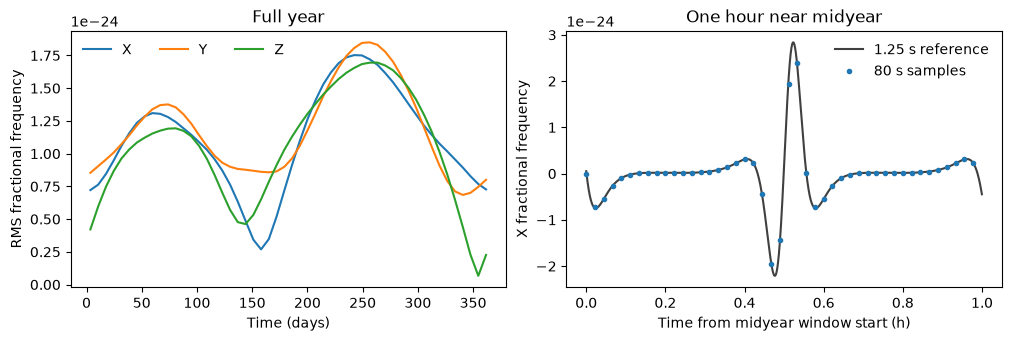

In [5]:
fig, (annual_ax, zoom_ax) = plt.subplots(1, 2, figsize=(10, 3.3), layout="constrained")

# RMS per weekly interval displays the annual modulation without aliasing the rapid oscillations.
weeks = np.array_split(np.arange(times.size), 52)
centres = [times[ix].mean() / day for ix in weeks]
rms = np.stack([np.sqrt(np.mean(xyz[:, ix]**2, axis=1)) for ix in weeks], axis=1)
for channel, values in zip("XYZ", rms):
    annual_ax.plot(centres, values, label=channel)
annual_ax.set(xlabel="Time (days)", ylabel="RMS fractional frequency", title="Full year")
annual_ax.legend(ncol=3, frameon=False)

fine_hours = (fine_times - fine_times[0]) / 3600
coarse_hours = (times[window] - fine_times[0]) / 3600
zoom_ax.plot(fine_hours[fine_hours < 1], fine[0, fine_hours < 1], color="0.25", label=f"{fine_dt:g} s reference")
zoom_ax.plot(coarse_hours[coarse_hours < 1], coarse[0, coarse_hours < 1], "o", ms=3,
             color="tab:blue", label=f"{dt:g} s samples")
zoom_ax.set(xlabel="Time from midyear window start (h)", ylabel="X fractional frequency", title="One hour near midyear")
zoom_ax.legend(frameon=False)
plt.show()

## 4. Use a common cadence for parameter estimation

For a prior that spans frequency and eccentricity, request one cadence for its full bounds. The lookup intersects the passing cadences at surrounding measured points. This supplies a grid to validate for the intended sky, masses, noise covariance and SNR. When comparing with data, use common physical frequency bins and account for any signal power above the template Nyquist frequency.

In [6]:
prior = recommend_cadence((1.0, 3.0), (0.10, 0.30), criterion="likelihood", snr=signal_snr)
if prior.cadence_s is None:
    print("No tested cadence passed across these bounds; a dedicated cadence check is needed.")
else:
    prior_grid = annual_pm_grid(source, cadence_s=prior.cadence_s)
    print(f"Common cadence for the example prior: {prior_grid.cadence_s:g} s")
    print(f"Calibration points used: {len(prior.checked_points)}")

Common cadence for the example prior: 35 s
Calibration points used: 6


## 5. Apply the response to several proposals

This short example keeps the first binary's frequency and eccentricity and uses its selected cadence. For a wider prior, use the common cadence above. Two sources share a sky direction and have different orbital phases and polarization angles. Prepare their projection once and apply it to their batched PM polarizations. Then move the second binary on the sky and reuse the detector with a separate projection for each source. In both examples, the first source should reproduce its individual annual XYZ values over the same day.

In [7]:
proposals = [source, replace(source, phi0=source.phi0 + 0.3, psi=source.psi + 0.2)]
segment = detector_at(times[window])
margin = source_margin_samples(segment)
batch = sampled_pm_batch(proposals, segment.times[0] - margin * dt, dt, window_samples + 2 * margin)
angles = jnp.array([s.psi for s in proposals])
fixed_sky = FixedSkyResponse.prepare(
    segment, source.propagation_direction(), *source.polarization_basis(),
    origin_s=batch.origin_s, dt_s=batch.dt_s, samples=batch.values.shape[-1],
)
same_sky_xyz = fixed_sky.apply(batch, angles)

# Intrinsic parameters and inclination stay fixed when we move only the sky.
skies = [proposals[0], replace(proposals[1], lambda_=proposals[1].lambda_ + 0.4)]
directions = jnp.asarray(np.stack([s.propagation_direction() for s in skies]))
plus, cross = (jnp.asarray(np.stack(tensors)) for tensors in zip(*(s.polarization_basis() for s in skies)))
different_sky_xyz, valid = sampled_response_batch_array(
    segment, batch.values, batch.origin_s, batch.dt_s, directions, plus, cross, angles,
    microbatch=len(skies),
)
assert np.asarray(valid).all()
for label, result in (("Shared sky", same_sky_xyz), ("Different skies", different_sky_xyz)):
    assert result.shape == (len(skies), 3, window_samples)
    # Annual and one-day calls solve the PM orbit on different integration spans.
    err = np.linalg.norm(np.asarray(result[0]) - coarse, axis=-1) / np.linalg.norm(coarse, axis=-1)
    print(f"{label}: XYZ shape {result.shape}; first source vs annual segment: {err.max():.2e}")

single = sampled_pm_uniform(skies[1], float(batch.origin_s), dt, batch.values.shape[-1])
independent = xyz_for(segment, single, skies[1])
batch_error = np.linalg.norm(np.asarray(different_sky_xyz[1]) - independent, axis=-1) / np.linalg.norm(independent, axis=-1)
assert batch_error.max() < 1e-10
print(f"Second sky vs its individual XYZ call: {batch_error.max():.2e}")

Shared sky: XYZ shape (2, 3, 1080); first source vs annual segment: 4.56e-15
Different skies: XYZ shape (2, 3, 1080); first source vs annual segment: 4.54e-15


Second sky vs its individual XYZ call: 6.70e-15


For the calibration domain, the annual numerical-orbit checks, and measured A100 timings, see the [cadence and batching guide](../../docs/annual_cadence.md).